
$P(x_j \mid x_{-j}) = \frac{P(x_{1:T})}{P(x_{-j})}$

上式可以通过x_j 前后的观测值预测x_j 
HMM 可以解决上述问题 通过加上一层 隐藏变量 结合 DP (Dynamic Programaing)

观测：x_1,...,x_T
人为加一条对齐的隐状态：h_t ∈ {1,...,k}（离散，不是 RNN 的 H）
一阶马尔可夫在 h 上：P(h_{t+1}|h_{1:t},x_{1:t})=P(h_{t+1}|h_t)
（只留 h_t，因为它是 h_{t+1} 的父节点）
发射：P(x_t|h_t)

联合（一条 h 组合）：P(x,h)=∏_t P(h_t|h_{t-1}) P(x_t|h_t)

目标是填空：P(x_j | x_左, x_右)= 分子/分母
分子 P(x_{1:T})=∑_h P(x,h)=∑_h ∏_t ...   （把 h 积掉）
分母 P(x_左,x_右)=∑_{x_j} 分子

穷举 ∑_h 是 k^T。DP（前向 π_t）算同一个和，O(Tk^2)。
本节用 HMM+DP 对照：离散 h 太死；填空要看两边 → 后面用双向 RNN。




影藏变量的由来

认为观测数据背后存在一个我没有直接观察到的因素，而这个因素能够解释观测数据。”

KeyboardInterrupt: 

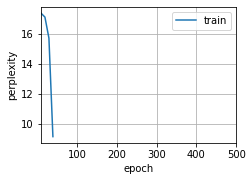

In [1]:
import torch
from torch import nn
from d2l import torch as d2l

# 加载数据
batch_size, num_steps, device = 32, 35, d2l.try_gpu()
train_iter, vocab = d2l.load_data_time_machine(batch_size, num_steps)
# 通过设置“bidirective=True”来定义双向LSTM模型
vocab_size, num_hiddens, num_layers = len(vocab), 256, 2
num_inputs = vocab_size
lstm_layer = nn.LSTM(num_inputs, num_hiddens, num_layers, bidirectional=True)
model = d2l.RNNModel(lstm_layer, len(vocab))
model = model.to(device)
# 训练模型
num_epochs, lr = 500, 1
d2l.train_ch8(model, train_iter, vocab, lr, num_epochs, device)